In [19]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict, Counter
import pandas as pd
import random
from tqdm import tqdm
from PIL import Image
import math
import shutil

# **PREPROCESAMIENTO**

In [20]:
data_path = r"C:\Users\Victoria\Desktop\Datos ICBA Filtered"
classes   = ["Am", "HTA", "EAo", "MCH"]
valid_ext = (".jpg", ".jpeg")

colors_map = {
    "Am":     "#B11919",
    "HTA":    "#F16666",
    "EAo":    "#0C4AA6",
    "MCH":    "#CAE8F9"
}

## **Recorte de márgenes**

Con el objetivo de eliminar de las imágenes los márgenes blancos, encabezados y pies de página que no contienen información relevante para el análisis, se implementó una etapa de recorte automático. Se busca conservar únicamente la región correspondiente a la grilla del electrocardiograma, incluyendo tanto las trazas de las doce derivaciones como los pulsos de calibración. Para esto se define la función `crop_ecg`, basada en la detección de las líneas mediante la Transformada de Hough Probabilística. 

En primer lugar, la imagen se procesa mediante el detector de bordes de Canny y posteriormente se aplica la Transformada de Hough Probabilística para identificar segmentos de recta. Con el fin de evitar detecciones espurias, se descartan los segmentos de corta longitud, que suelen corresponder al trazado de las señales de ECG o a falsas detecciones producidas por ruido. A continuación, se conservan únicamente aquellos segmentos cuyo ángulo se encuentra comprendido entre 85° y 95°, es decir, prácticamente verticales.

Los límites superior e inferior del recorte se estiman a partir de la mediana de las coordenadas extremas de los segmentos detectados. Dado que las líneas verticales de la grilla se extienden prácticamente a lo largo de toda la altura de la región útil del electrocardiograma, su detección permite localizar con precisión los límites de la zona que contiene la información clínica. Además, el empleo de la mediana proporciona robustez frente a detecciones erróneas aisladas, ya que la gran cantidad de líneas presentes en la grilla hace que unos pocos segmentos mal detectados no modifiquen significativamente el resultado final.

El recorte se realizó únicamente sobre los márgenes superior e inferior. No se efectuó recorte en los laterales, ya que el análisis del dataset mostró que los márgenes blancos en esa dirección son reducidos y no justifican una etapa adicional de procesamiento.

En algunas imágenes de menor resolución, las líneas de la grilla presentan un espesor de aproximadamente un píxel, dificultando su detección mediante el algoritmo de Canny. Para estos casos se incorporó una etapa previa de escalado de la imagen por un factor dos. Este aumento de resolución mejora la detección de los bordes de la grilla sin modificar su estructura geométrica. Finalmente, las coordenadas del recorte obtenidas sobre la imagen escalada se reescalan a las dimensiones originales antes de realizar el corte definitivo.

In [21]:
def crop_ecg(img, debug=False):

    height, width = img.shape[:2]

    if min(height, width) < 1000:
        scale   = 2.0
        img_det = cv2.resize(img, None, fx=scale, fy=scale, interpolation=cv2.INTER_CUBIC)
    else:
        scale   = 1.0
        img_det = img

    h_det = img_det.shape[0]
    gray  = cv2.cvtColor(img_det, cv2.COLOR_BGR2GRAY)
    edges = cv2.Canny(gray, 50, 150)

    min_length = int(h_det * 0.30)
    lines = cv2.HoughLinesP(edges, 1, np.pi / 180,
                            threshold=60,
                            minLineLength=min_length,
                            maxLineGap=15)

    detected = False

    if lines is not None:
        candidates = []
        for line in lines:
            x1, y1, x2, y2 = line[0]
            angle = abs(np.arctan2(y2 - y1, x2 - x1) * 180 / np.pi)
            if 85 < angle < 95:
                candidates.append(line[0])

        if candidates:
            y_tops    = [min(l[1], l[3]) for l in candidates]
            y_bottoms = [max(l[1], l[3]) for l in candidates]

            pad         = int(h_det * 0.01)
            y_final_top = max(0,      int(np.median(y_tops))    - pad)
            y_final_bot = min(h_det,  int(np.median(y_bottoms)) + pad)

            y_final_top = int(y_final_top / scale)
            y_final_bot = int(y_final_bot / scale)

            detected = True

    if not detected:
        if debug:
            return {"detected": False, "original": img, "cropped": img,
                    "y_min": 0, "y_max": height}
        return img

    cropped = img[y_final_top:y_final_bot, :]

    if debug:
        det_img = img.copy()
        for s in candidates:
            sx1, sy1, sx2, sy2 = [int(v / scale) for v in s]
            cv2.line(det_img, (sx1, sy1), (sx2, sy2), (166, 74, 12), 2)
        return {"detected": True, "original": img, "detection": det_img,
                "y_min": y_final_top, "y_max": y_final_bot, "cropped": cropped}

    return cropped

A continuación se presentan algunos ejemplos del recorte automático aplicado sobre imágenes del dataset. Puede observarse que el procedimiento elimina correctamente los márgenes superiores e inferiores, conservando íntegramente la región correspondiente a la grilla del electrocardiograma.

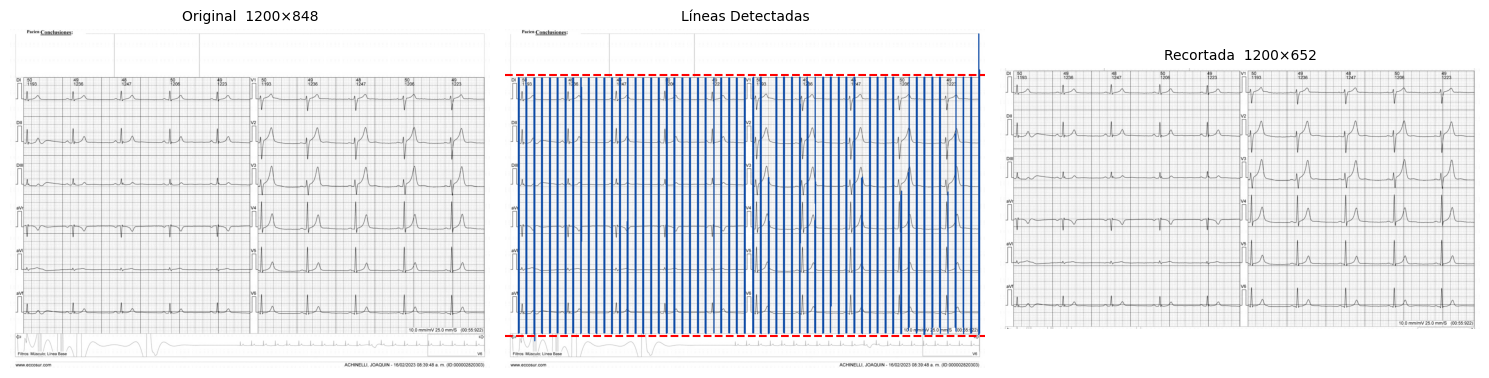

In [105]:
def plot_crop(data_path, classes, n_imagenes=8, valid_ext=(".jpg", ".jpeg", ".png")):
    all_paths = []
    for cls in classes:
        cls_path = os.path.join(data_path, cls)
        if not os.path.exists(cls_path):
            continue
        for f in os.listdir(cls_path):
            if os.path.splitext(f)[1].lower() in valid_ext:
                all_paths.append((cls, os.path.join(cls_path, f)))

    selected = random.sample(all_paths, min(n_imagenes, len(all_paths)))

    fig, axs = plt.subplots(len(selected), 3, figsize=(15, 4.5 * len(selected)), squeeze=False)

    for i, (cls_name, path) in enumerate(selected):
        img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            continue
        h, w   = img.shape[:2]
        res    = crop_ecg(img, debug=True)
        cropped = res["cropped"]
        ch, cw  = cropped.shape[:2]
        y_min, y_max = res["y_min"], res["y_max"]

        axs[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axs[i, 0].set_title(f"Original  {w}×{h}", fontsize=10, y=1)
        axs[i, 0].axis("off")

        axs[i, 1].imshow(cv2.cvtColor(res.get("detection", img), cv2.COLOR_BGR2RGB))
        axs[i, 1].axhline(y_min, color="red", linestyle="--", linewidth=1.5)
        axs[i, 1].axhline(y_max, color="red", linestyle="--", linewidth=1.5)
        axs[i, 1].set_title(f"Líneas Detectadas", fontsize=10, y=1)
        axs[i, 1].axis("off")

        axs[i, 2].imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
        axs[i, 2].set_title(f"Recortada  {cw}×{ch}", fontsize=10, y=1)
        axs[i, 2].axis("off")

    plt.tight_layout()
    plt.show()

plot_crop(data_path, classes, n_imagenes=1)

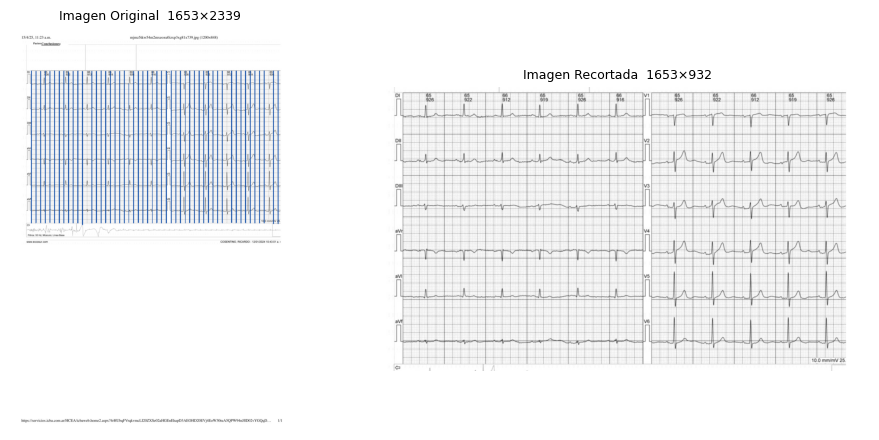

In [103]:
def plot_crop(data_path, classes, n_imagenes=8, valid_ext=(".jpg", ".jpeg", ".png")):
    all_paths = []
    for cls in classes:
        cls_path = os.path.join(data_path, cls)
        if not os.path.exists(cls_path):
            continue
        for f in os.listdir(cls_path):
            if os.path.splitext(f)[1].lower() in valid_ext:
                all_paths.append((cls, os.path.join(cls_path, f)))

    selected = random.sample(all_paths, min(n_imagenes, len(all_paths)))

    fig, axs = plt.subplots(len(selected), 2, figsize=(10, 4.5 * len(selected)), squeeze=False)

    for i, (cls_name, path) in enumerate(selected):
        img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            continue
        h, w  = img.shape[:2]
        res   = crop_ecg(img, debug=True)
        cropped = res["cropped"]
        ch, cw  = cropped.shape[:2]

        axs[i, 0].imshow(cv2.cvtColor(res.get("detection", img), cv2.COLOR_BGR2RGB))
        axs[i, 0].set_title(f"Imagen Original  {w}×{h} ", fontsize=9, y=1)
        axs[i, 0].axis("off")

        axs[i, 1].imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
        axs[i, 1].set_title(f"Imagen Recortada  {cw}×{ch}", fontsize=9, y=1)
        axs[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

plot_crop(data_path, classes, n_imagenes=1)

Para verificar que el recorte automático sea consistente a lo largo del dataset, se analizó la **relación de aspecto** (ancho / alto) de cada imagen recortada. Dado que todas las imágenes corresponden al mismo formato de ECG de 12 derivaciones en disposición 6×2, la grilla tiene proporciones similares en todos los casos, por lo tanto, un recorte correcto debería producir imágenes con relaciones de aspecto comparables entre sí, independientemente del tamaño original de la imagen o de si fue tomada en orientación horizontal o vertical.

Se consideran **outliers** aquellas imágenes cuya relación de aspecto difiere en más de dos desvíos estándar de la media del conjunto. Este criterio estadístico estándar identifica los valores genuinamente atípicos, equivalente al 5% más extremo bajo una distribución normal.

In [22]:
def get_aspect_ratios(data_path, classes, valid_ext=(".jpg", ".jpeg", ".png")):
    resultados = []
    for cls in classes:
        cls_path = os.path.join(data_path, cls)
        if not os.path.exists(cls_path):
            continue
        for f in os.listdir(cls_path):
            if os.path.splitext(f)[1].lower() not in valid_ext:
                continue
            img = cv2.imdecode(np.fromfile(os.path.join(cls_path, f), dtype=np.uint8), cv2.IMREAD_COLOR)
            if img is None:
                continue
            h_orig, w_orig = img.shape[:2]
            cropped = crop_ecg(img)
            h_crop, w_crop = cropped.shape[:2]
            resultados.append({
                "clase": cls, "archivo": f,
                "h_orig": h_orig, "w_orig": w_orig,
                "h_crop": h_crop, "w_crop": w_crop,
                "ratio_ar": w_crop / h_crop
            })
    return pd.DataFrame(resultados)


df_crops = get_aspect_ratios(data_path, classes)

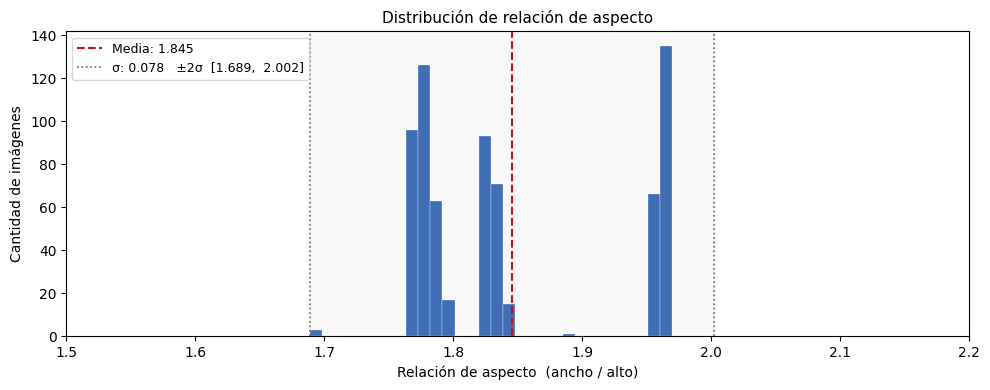

In [23]:
def plot_aspect_ratios(df):
    media   = df["ratio_ar"].mean()
    std     = df["ratio_ar"].std()
    lim_inf = media - 2 * std
    lim_sup = media + 2 * std

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(df["ratio_ar"], bins=30, color="#0C4AA6", alpha=0.8,
            edgecolor="white", linewidth=0.3)
    ax.axvline(media,   color="#B11919",   lw=1.5, linestyle="--", label=f"Media: {media:.3f}")
    ax.axvline(lim_inf, color="dimgray", lw=1.2, linestyle=":",  label=f"σ: {std:.3f}   ±2σ  [{lim_inf:.3f},  {lim_sup:.3f}]")
    ax.axvline(lim_sup, color="dimgray", lw=1.2, linestyle=":")
    ax.axvspan(lim_inf, lim_sup, alpha=0.05, color="gray")
    ax.set_xlim(1.5, 2.20)
    ax.set_xlabel("Relación de aspecto  (ancho / alto)", fontsize=10)
    ax.set_ylabel("Cantidad de imágenes", fontsize=10)
    ax.set_title("Distribución de relación de aspecto", fontsize=11)
    ax.legend(fontsize=9, loc="upper left")
    plt.tight_layout()
    plt.show()


plot_aspect_ratios(df_crops)

Las imágenes identificadas como outliers se inspeccionan visualmente para determinar si el recorte fue incorrecto o no. Se comprobó que las diferencias observadas obedecían a variaciones propias de la imagen original y no a fallas del algoritmo. En todos los casos, la región de interés fue delimitada correctamente, por lo que el procedimiento se consideró válido para la totalidad del dataset.

Outliers: 2  (AR < 1.689  o  AR > 2.002)


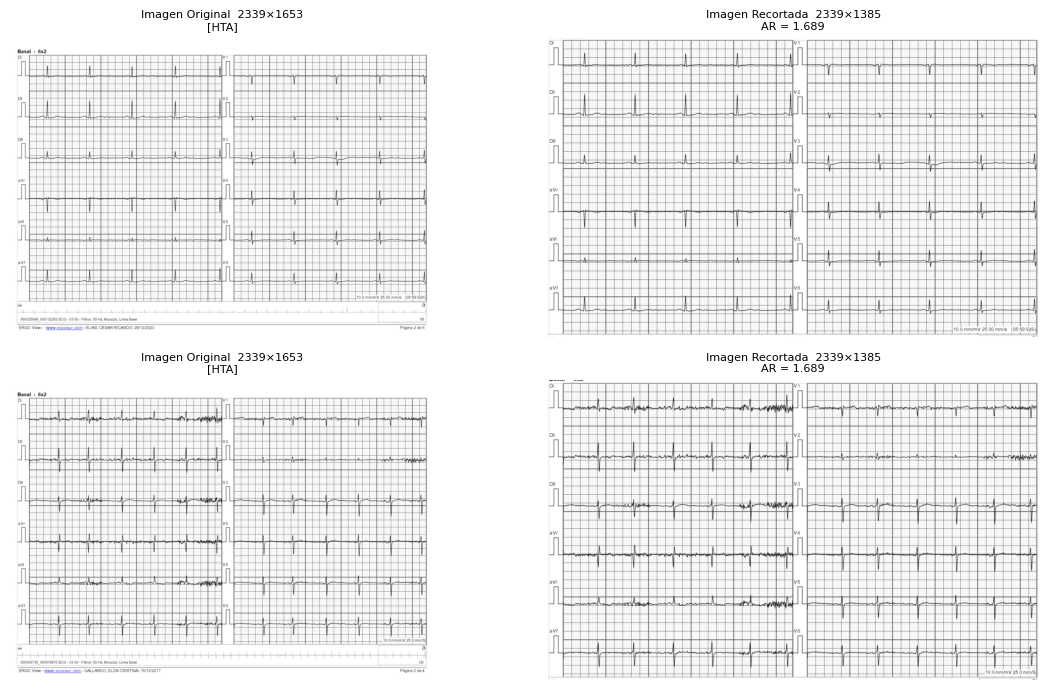

In [24]:
def plot_outliers(df, data_path, valid_ext=(".jpg", ".jpeg", ".png")):
    media   = df["ratio_ar"].mean()
    std     = df["ratio_ar"].std()
    lim_inf = media - 2 * std
    lim_sup = media + 2 * std
    outliers = df[(df["ratio_ar"] < lim_inf) | (df["ratio_ar"] > lim_sup)].sort_values("ratio_ar")

    print(f"Outliers: {len(outliers)}  (AR < {lim_inf:.3f}  o  AR > {lim_sup:.3f})")

    if len(outliers) == 0:
        print("No se encontraron outliers.")
        return

    fig, axs = plt.subplots(len(outliers), 2,
                            figsize=(12, 3.5 * len(outliers)), squeeze=False)

    for i, (_, row) in enumerate(outliers.iterrows()):
        path = os.path.join(data_path, row["clase"], row["archivo"])
        img = cv2.imdecode(np.fromfile(path, dtype=np.uint8), cv2.IMREAD_COLOR)
        if img is None:
            continue
        cropped = crop_ecg(img)
        h, w = row["h_orig"], row["w_orig"]

        axs[i, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axs[i, 0].set_title(f"Imagen Original  {w}×{h}\n[{row['clase']}]", fontsize=8)
        axs[i, 0].axis("off")

        axs[i, 1].imshow(cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB))
        axs[i, 1].set_title(f"Imagen Recortada  {row['w_crop']}×{row['h_crop']}\nAR = {row['ratio_ar']:.3f}", fontsize=8)
        axs[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

plot_outliers(df_crops, data_path)

In [25]:
print(df_crops.groupby(['w_orig', 'h_orig'])[['ratio_ar', 'w_crop', 'h_crop']].mean().round(3))

               ratio_ar  w_crop    h_crop
w_orig h_orig                            
1200   848        1.837  1200.0   653.333
1653   2339       1.779  1653.0   929.434
1654   2339       1.781  1654.0   928.833
1700   2200       1.827  1700.0   930.417
2200   1700       1.963  2200.0  1121.000
2339   1653       1.932  2339.0  1211.702


Una vez teniendo verificado el desempeño de la función `crop_ecg`, la aplicamos sobre el total de las imágenes del dataset. Las imágenes recortadas se guardan en una nueva carpeta llamada Datos ICBA Cropped.

In [6]:
cropped_path = r"C:\Users\Victoria\Desktop\Datos ICBA Cropped"

In [ ]:
errores_crop = []
ok_crop      = 0

all_files_crop = [
    (cls, f)
    for cls in classes
    for f in os.listdir(os.path.join(data_path, cls))
    if os.path.splitext(f)[1].lower() in valid_ext
]

print(f"Imágenes a procesar: {len(all_files_crop)}")

for cls, fname in tqdm(all_files_crop):
    src     = os.path.join(data_path, cls, fname)
    dst_dir = os.path.join(cropped_path, cls)
    os.makedirs(dst_dir, exist_ok=True)
    dst     = os.path.join(dst_dir, fname)

    img = cv2.imdecode(np.fromfile(src, dtype=np.uint8), cv2.IMREAD_COLOR)
    if img is None:
        errores_crop.append(f"No se pudo leer: {src}")
        continue

    cropped = crop_ecg(img)

    success, buf = cv2.imencode('.jpg', cropped)
    if success:
        buf.tofile(dst)
        ok_crop += 1
    else:
        errores_crop.append(f"No se pudo guardar: {dst}")

print(f"\nGuardadas: {ok_crop}/{len(all_files_crop)}")
if errores_crop:
    print(f"Errores ({len(errores_crop)}):")
    for e in errores_crop:
        print(f"  {e}")

## **Redimensionamiento**

Las redes neuronales convolucionales requieren que todas las imágenes de entrada tengan el mismo tamaño. Con el objetivo de reducir el costo computacional del entrenamiento, se buscó determinar el tamaño mínimo al que es posible reducir las imágenes sin que la pérdida de resolución implique pérdida de información diagnósticamente relevante.

Una práctica habitual en visión computacional es utilizar imágenes cuadradas. Esta convención tiene origen en que los principales benchmarks de clasificación de imágenes emplean imágenes cuadradas, por lo que las arquitecturas más utilizadas fueron diseñadas, preentrenadas y evaluadas con este formato de entrada. Adoptar imágenes cuadradas maximiza la compatibilidad con los pesos preentrenados disponibles, lo que resulta especialmente relevante en este trabajo dado que se emplea transfer learning.

A continuación se comparan visualmente distintos tamaños estándar para evaluar el nivel de detalle conservado en cada caso.


In [15]:
img_ref_path = r"C:\Users\Victoria\Desktop\Datos ICBA Cropped\Am\Am_3.jpg"
img_orig     = Image.open(img_ref_path).convert("L")
orig_w, orig_h = img_orig.size

In [16]:
def plot_grid_2col(images_titles, suptitle):
    fig, axes = plt.subplots(2, 3, figsize=(16, 9))
    axes = axes.flatten()
    for i, (img, title) in enumerate(images_titles):
        axes[i].imshow(img, cmap="gray")
        axes[i].set_title(title, fontsize=13)
        axes[i].axis("off")
    for j in range(len(images_titles), 6):
        axes[j].axis("off")
    plt.suptitle(suptitle, fontsize=24, y=1)
    plt.tight_layout()
    plt.show()

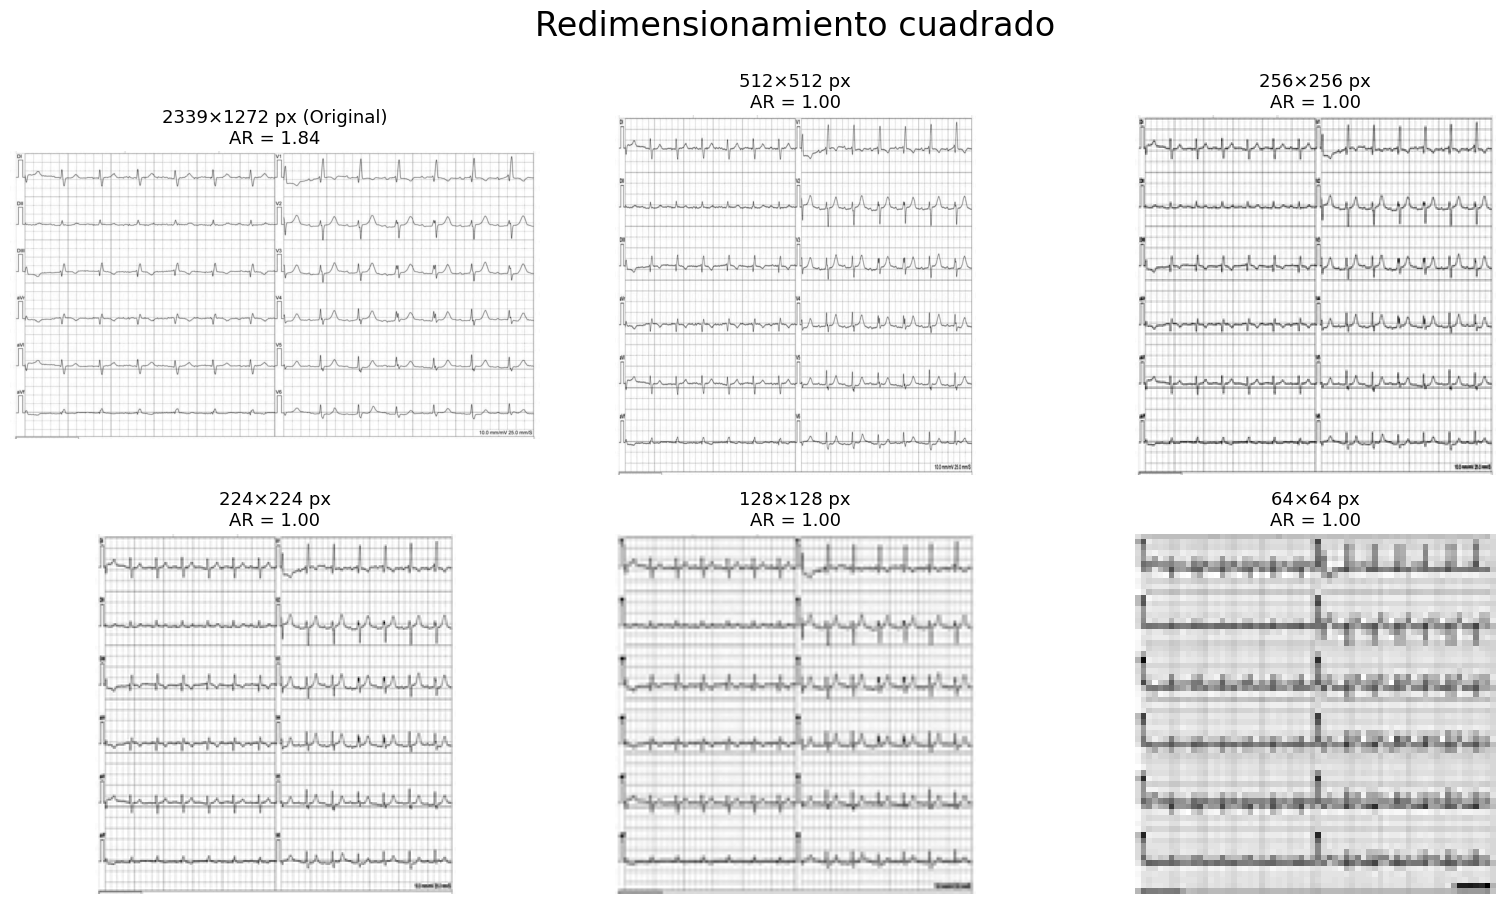

In [17]:
square_sizes = [512, 256, 224, 128, 64]
items_sq = [(img_orig, f"{orig_w}×{orig_h} px (Original)\nAR = {orig_w/orig_h:.2f}")]
for s in square_sizes:
    resized = img_orig.resize((s, s), Image.LANCZOS)
    items_sq.append((resized, f"{s}×{s} px\nAR = 1.00"))


plot_grid_2col(items_sq, "Redimensionamiento cuadrado")

Sin embargo, la imagen de ECG tiene una estructura rectangular intrínseca. El eje horizontal representa la dimensión temporal de la señal, mientras que el eje vertical corresponde a la amplitud. Al comprimir la imagen a un formato cuadrado se contrae el eje temporal, lo que equivale a distorsionar la escala temporal de la señal. Esta deformación podría dificultar la identificación de características diagnósticamente relevantes.

Por estas razones, se optó por un **redimensionamiento rectangular** que preserve en la mayor medida posible la relación de aspecto original de las imágenes. Para garantizar compatibilidad con las arquitecturas convolucionales utilizadas, las dimensiones de entrada deben ser múltiplos de 32. La mayoría de las CNN modernas realizan sucesivas reducciones espaciales con pooling de stride 2, lo que implica que las dimensiones de la imagen se dividen sucesivamente por 2 en cada etapa. Si el tamaño de entrada no es múltiplo de 2⁵ = 32, pueden producirse truncamientos o necesidad de padding que introduzcan artefactos. 

A continuación se evalúan distintas opciones rectangulares de múltiplos de 32 con relaciones de aspecto cercanas a la media observada en el dataset (≈ 1.845).


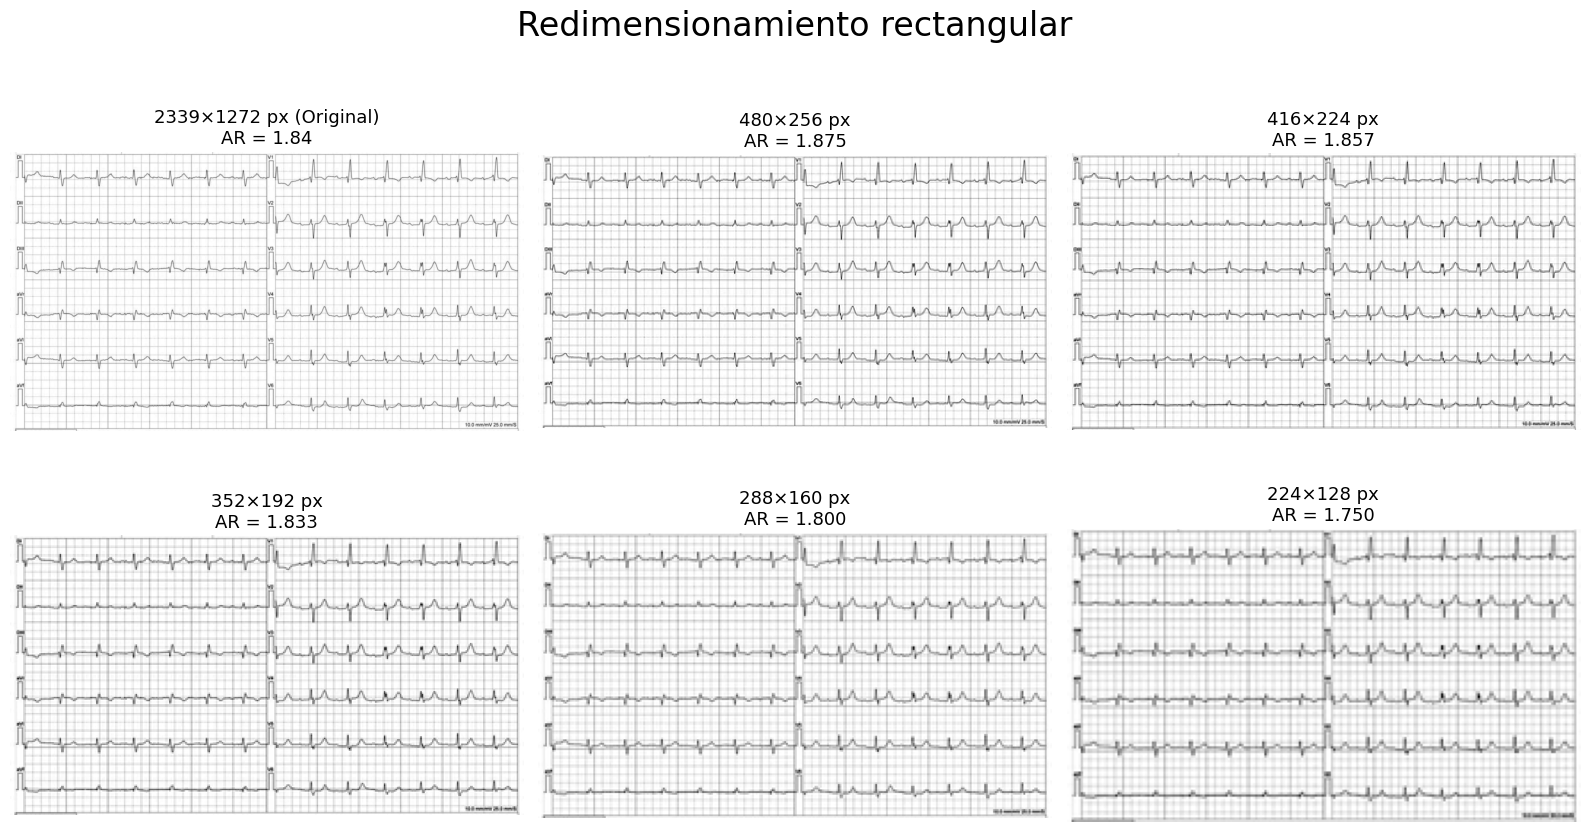

In [18]:
rect_sizes = [
    (256, 480),   # AR = 1.875
    (224, 416),   # AR = 1.857
    (192, 352),   # AR = 1.833  ← elegido
    (160, 288),   # AR = 1.800
    (128, 224),   # AR = 1.750
]
items_ar = [(img_orig, f"{orig_w}×{orig_h} px (Original)\nAR = {orig_w/orig_h:.2f}")]
for h, w in rect_sizes:
    resized = img_orig.resize((w, h), Image.LANCZOS)
    items_ar.append((resized, f"{w}×{h} px\nAR = {w/h:.3f}"))

plot_grid_2col(items_ar, "Redimensionamiento rectangular")


Considerando conjuntamente la preservación de la información visual, la proximidad de la relación de aspecto al valor medio del dataset y el costo computacional asociado al entrenamiento, se seleccionó un tamaño de entrada de 192 × 352 píxeles. Esta resolución constituye un equilibrio adecuado entre fidelidad geométrica y eficiencia computacional, ya que minimiza la distorsión introducida durante el redimensionamiento y evita el incremento innecesario en el consumo de memoria y el tiempo de entrenamiento que implican resoluciones mayores. En particular, la resolución inmediatamente superior evaluada, 224 × 416 píxeles, presenta una relación de aspecto igualmente cercana a la original, pero no aporta una mejora visual significativa que justifique el incremento en el costo computacional.

A continuación, se aplica el redimensionamiento a todas las imágenes del Dataset ICBA.

In [12]:
resized_path = r"C:\Users\Victoria\Desktop\Datos ICBA Resized"
IMG_W        = 352
IMG_H        = 192

In [ ]:
for cls in classes:
    src_dir = os.path.join(cropped_path, cls)
    dst_dir = os.path.join(resized_path, cls)
    os.makedirs(dst_dir, exist_ok=True)
    files = sorted(f for f in os.listdir(src_dir) if f.lower().endswith(valid_ext))
    for fname in tqdm(files, desc=cls):
        dst = os.path.join(dst_dir, fname)
        if os.path.exists(dst):
            continue
        img = Image.open(os.path.join(src_dir, fname)).convert("L")
        img.resize((IMG_W, IMG_H), Image.LANCZOS).save(dst, "JPEG", quality=95)

print("\nImágenes en Datos ICBA Resized:")
for cls in classes:
    print(f"  {cls}: {len(os.listdir(os.path.join(resized_path, cls)))}")


## **Split del Dataset**

Las imágenes redimensionadas se dividen en dos etapas. Primero se separa un **20% por clase como conjunto de test** (completamente reservado para la evaluación final, nunca utilizado durante el entrenamiento ni la búsqueda de hiperparámetros). Luego, el **80% restante** en 5 folds de forma estratificada (con semilla fija), garantizando que cada fold conserve aproximadamente la misma proporción de imágenes por clase.

In [13]:
dataset_path = r"C:\Users\Victoria\Desktop\Dataset ICBA Folds"

TEST_SIZE    = 0.20
N_FOLDS      = 5
SEED         = 42

In [14]:
random.seed(SEED)

for cls in classes:
    src_dir = os.path.join(resized_path, cls)
    files   = sorted(f for f in os.listdir(src_dir) if f.lower().endswith('.jpg'))
    random.shuffle(files)

    n_test      = round(len(files) * TEST_SIZE)
    test_files  = files[:n_test]
    train_files = files[n_test:]

    # Guardar test (skip si ya existe)
    for fname in test_files:
        dst = os.path.join(dataset_path, 'test', cls, fname)
        if not os.path.exists(dst):
            os.makedirs(os.path.dirname(dst), exist_ok=True)
            shutil.copy2(os.path.join(src_dir, fname), dst)

    # Distribuir en folds round-robin (skip si ya existe)
    folds = [[] for _ in range(N_FOLDS)]
    for i, f in enumerate(train_files):
        folds[i % N_FOLDS].append(f)

    for fold_idx, fold_files in enumerate(folds, start=1):
        for fname in fold_files:
            dst = os.path.join(dataset_path, 'train', f"fold {fold_idx}", cls, fname)
            if not os.path.exists(dst):
                os.makedirs(os.path.dirname(dst), exist_ok=True)
                shutil.copy2(os.path.join(src_dir, fname), dst)

print('Split completado.')

Split completado.


In [15]:
header = f"{'Clase':<10}  {'test':>6}  {'train':>6}" + "".join(f"  fold {i+1}" for i in range(N_FOLDS)) + "   TOTAL"
print(header)
print("-" * len(header))

for cls in classes:
    n_test = len(os.listdir(os.path.join(dataset_path, 'test', cls))) \
             if os.path.exists(os.path.join(dataset_path, 'test', cls)) else 0
    counts = []
    for fold_idx in range(1, N_FOLDS + 1):
        fold_dir = os.path.join(dataset_path, 'train', f"fold {fold_idx}", cls)
        counts.append(len(os.listdir(fold_dir)) if os.path.exists(fold_dir) else 0)
    n_train = sum(counts)
    print(f"{cls:<10}  {n_test:>6}  {n_train:>6}" + "".join(f"  {c:>6}" for c in counts) + f"   {n_test + n_train:>5}")

Clase         test   train  fold 1  fold 2  fold 3  fold 4  fold 5   TOTAL
--------------------------------------------------------------------------
Am              37     149      30      30      30      30      29     186
HTA             36     142      29      29      28      28      28     178
EAo             38     154      31      31      31      31      30     192
MCH             26     104      21      21      21      21      20     130
Normal          18      70      14      14      14      14      14      88
